# Capítulo 3 · Actividad: análisis de datos con NumPy, pandas y matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/01_actividad_numpy_pandas.ipynb)

En esta actividad haces de **analista de datos**: vas a responder preguntas sobre datos reales con **NumPy** y **pandas**, y después los visualizarás con **matplotlib** y **seaborn**. Lo importante no es solo que el código funcione, sino que **sepas interpretar los resultados**.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia. Si editas el original tendrás conflictos al sincronizar tu fork.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```
3. Ten a mano las notebooks de clase de `notebooks/lectures/chapter_03/`: `01_numpy`, `02_pandas` y `03_matplotlib`.

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Puedes añadir todas las celdas que necesites.
- En las celdas ✍️ responde con tus palabras y **apoya tus respuestas con números** de tus resultados.
- En las partes 1 y 2, las 💡 **pistas** te recuerdan funciones. Si una función no salió en clase, la pista explica cómo usarla. La parte 3 no tiene pistas.
- Al terminar, ejecuta **Kernel → Restart & Run All** y comprueba que todo funciona de arriba abajo.

| Parte | Datos | Herramienta |
|---|---|---|
| 1. La cafetería | ventas de un mes (generadas en la notebook) | NumPy |
| 2. Las propinas | `data/tips.csv` | pandas (+ un poco de NumPy) |
| 3. Visualización | cafetería, propinas y `data/penguins.csv` | matplotlib y seaborn |

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"
print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: /home/joseph/Proyectos/SamsungInnovation-1-/data


---
## Parte 1 · La cafetería ☕ (NumPy)

Una cafetería vende 5 productos y ha registrado cuántas unidades vendió de cada uno durante **4 semanas** (28 días, de lunes a domingo). La dueña quiere saber cuánto gana, qué días van mejor y qué producto le conviene más.

Ejecuta la siguiente celda para generar los datos. **No hace falta que la modifiques ni que entiendas cada línea.**

In [3]:
# Datos de la cafetería (no hace falta modificar esta celda)
rng = np.random.default_rng(42)

productos = np.array(["café", "latte", "té", "croissant", "sándwich"])
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])       # precio de cada producto, en $

# Unidades vendidas cada día: los fines de semana se vende un 50% más
dia_semana = np.tile(np.arange(7), 4)                # 0 = lunes, ..., 6 = domingo
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])     # ventas esperadas por día y producto
ventas_planas = rng.poisson(promedio).ravel()         # ¡todo en una sola fila!

print(ventas_planas[:10], "...")
print("Número de valores:", ventas_planas.size)

[35 28  7 16 13 29 16 10 18 11] ...
Número de valores: 140


### Ejercicio 1 · Dar forma a los datos

`ventas_planas` tiene 140 números seguidos: primero las ventas de los 5 productos del día 1, después las del día 2, y así sucesivamente.

a) Crea una matriz `ventas` con forma `(28, 5)`: una **fila por día** y una **columna por producto** (en el mismo orden que `productos`).

b) Imprime su `shape`, `ndim`, `size` y `dtype`.

c) ¿Cuántos cafés se vendieron el primer día? Comprueba que coincide con `ventas_planas[0]`.

> 💡 **Pista:** `reshape`.

In [4]:
# Tu código aquí
ventas=ventas_planas.reshape(28,5)
print("Dimesion:",ventas.shape)
print("Numero de dimensiones:", ventas.ndim)
print("Tamaño:",ventas.size)
print("Typo:", ventas.dtype)
ventas[0,0]==ventas_planas[0]

Dimesion: (28, 5)
Numero de dimensiones: 2
Tamaño: 140
Typo: int64


np.True_

### Ejercicio 2 · Indexación

Obtén, usando índices y *slicing* sobre `ventas`:

a) Las ventas de todos los productos el **primer día**.

b) Las ventas de **latte** (columna 1) durante todo el mes.

c) Las ventas de la **última semana** (los últimos 7 días). Comprueba que su forma es `(7, 5)`.

d) Las ventas de **croissant y sándwich** (las dos últimas columnas) durante la **primera semana**.

> 💡 **Pista:** `M[filas, columnas]`. Recuerda que los índices negativos cuentan desde el final.

In [5]:
# Tu código aquí
#print(ventas)
ventas[0,:] #Ventas de todos los productos el primer dia
ventas[:,1] #Ventas de latte
ultsem=ventas[-7::,:] #ventas de la ultima semana
ultsem.shape #comprobacion de dimension
ventas[:7,-2::]

array([[16, 13],
       [18, 11],
       [17, 10],
       [15,  8],
       [17,  8],
       [22, 14],
       [29, 12]])

### Ejercicio 3 · Ingresos

a) Calcula la matriz `ingresos` (forma `(28, 5)`): lo que se ingresó por cada producto cada día.

b) ¿Cuánto ingresó la cafetería en todo el mes?

c) Crea `ingreso_diario`, un array con el ingreso total de **cada día** (forma `(28,)`).

d) ¿Cuál fue el ingreso diario medio, el máximo y el mínimo?

> 💡 **Pistas:**
> - `ventas * precios` multiplica **cada fila** de `ventas` por el vector `precios`, elemento a elemento: la columna del café por 1.5, la del latte por 2.8… (este mecanismo se llama *broadcasting*).
> - `M.sum()` suma todo. `M.sum(axis=1)` suma **cada fila** y devuelve un resultado por fila; `M.sum(axis=0)` suma **cada columna**.

In [6]:
# Tu código aquí
ingresos=ventas*precios
print(ingresos.shape)
ingresos.sum() #ingreso total
ingreso_diario=ingresos.sum(axis=1)
print(ingreso_diario.shape)
ingreso_diario.mean(),ingreso_diario.max(),ingreso_diario.min()


(28, 5)
(28,)


(np.float64(226.5178571428572),
 np.float64(337.29999999999995),
 np.float64(165.89999999999998))

### Ejercicio 4 · Días buenos y días flojos

Usa este array con el número de cada día (del 1 al 28):
```python
dias = np.arange(1, 29)
```

a) Crea una máscara con los días cuyo ingreso supera el **ingreso diario medio** y muestra **qué días** fueron.

b) ¿**Cuántos** días fueron?

c) Crea un array que diga `"bueno"` o `"flojo"` para cada día, según si supera o no la media.

d) Calcula `dias[mascara] % 7` (el resto de dividir entre 7). El día 1 fue lunes, así que un resto de **6** es sábado y un resto de **0** es domingo. ¿Qué tienen en común los días buenos?

> 💡 **Pistas:** `.sum()` sobre una máscara cuenta los `True`, porque `True` vale 1 y `False` vale 0. Para c), `np.where`.

In [7]:
# Tu código aquí
dias=np.arange(1,29)
mascara= ingreso_diario > ingreso_diario.mean()
dias[mascara]
mascara.sum()


np.int64(11)

**Preguntar sobre que realizar**

In [8]:
bdias= dias[mascara] % 7

✍️ **Tu respuesta:** 

### Ejercicio 5 · Análisis por semanas

a) Reorganiza `ingreso_diario` en una matriz `por_semana` de forma `(4, 7)`: una fila por semana y una columna por día (lunes a domingo).

b) ¿Cuánto se ingresó **cada semana**?

c) ¿Cuál es el ingreso medio de **cada día de la semana**? ¿Qué día se vende más? Usa:
```python
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
```

d) Compara el ingreso medio de un día de **fin de semana** con el de un día **entre semana**. ¿Cuántas veces más se ingresa en fin de semana?

> 💡 **Pistas:** `axis=1` da un resultado por fila (por semana) y `axis=0` uno por columna (por día de la semana). `arr.argmax()` devuelve la **posición** del valor máximo; úsala como índice en `nombres_dias`.

#### Inciso a

In [9]:
ingreso_diario=ingreso_diario.reshape(4,7)


#### Inciso b

In [10]:
ingreso_diario.sum(axis=1)

array([1577.8, 1604.5, 1575.6, 1584.6])

#### Inciso C

In [11]:
ingreso_medio_d=ingreso_diario.mean(axis=0)
print(ingreso_medio_d)
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
nombres_dias[ingreso_medio_d.argmax()]

[191.625 195.2   191.175 195.9   200.75  302.95  308.025]


np.str_('domingo')

#### Inciso d

In [12]:
import random
finde=ingreso_medio_d[-2:]
sem=ingreso_medio_d[:-2]
finde[random.randint(0,1)]/sem[random.randint(0,4)]

np.float64(1.546452271567126)

### Ejercicio 6 · El producto estrella

a) Calcula el ingreso total de **cada producto** en el mes.

b) ¿Qué **porcentaje** del ingreso total aporta cada producto? Redondea a 1 decimal.

c) ¿Qué producto genera **más dinero**? ¿Y cuál vende **más unidades**?

> 💡 **Pista:** `axis=0` y `argmax`, igual que en el ejercicio anterior.

#### a) Calcula el ingreso total de **cada producto** en el mes.

In [13]:
ingresoP=ingresos.sum(axis=0)
print(ingresoP)

[1483.5 2018.8  457.2 1114.  1269. ]


#### b) ¿Qué **porcentaje** del ingreso total aporta cada producto? Redondea a 1 decimal.

In [14]:
ingresoT=ingresos.sum()
porcentajep=np.round(((ingresoP*100)/ingresoT),1)
for i,producto in enumerate(productos):
    print(producto,":", porcentajep[i])

café : 23.4
latte : 31.8
té : 7.2
croissant : 17.6
sándwich : 20.0


#### c) ¿Qué producto genera **más dinero**? ¿Y cuál vende **más unidades**?


In [15]:
MasDinero=productos[ingresoP.argmax()]
MasUnidades=productos[np.argmax(ventas.sum(axis=0))]
print("El que mas dinero da es:",MasDinero,
      " y el de mas unidades es:",MasUnidades)

El que mas dinero da es: latte  y el de mas unidades es: café


✍️ **Pregunta:** ¿por qué el producto que más se vende no es el que más dinero deja? Si fueras la dueña, ¿qué harías con esta información?

✍️ **Tu respuesta:** 

---
## Parte 2 · Las propinas 💵 (pandas)

Un camarero anotó, durante varias semanas, cada mesa que atendió: cuánto pagaron, cuánta propina dejaron y algunos datos de la mesa. Queremos responder una pregunta: **¿de qué depende la propina?**

El archivo es `data/tips.csv` y tiene estas columnas:

| Columna | Significado |
|---|---|
| `total_bill` | importe de la cuenta, en $ |
| `tip` | propina, en $ |
| `sex` | sexo de quien pagó (`Female` / `Male`) |
| `smoker` | si en la mesa había fumadores (`Yes` / `No`) |
| `day` | día de la semana (`Thur`, `Fri`, `Sat`, `Sun`) |
| `time` | `Lunch` (comida) o `Dinner` (cena) |
| `size` | número de personas en la mesa |

### Ejercicio 7 · Primer vistazo

a) Carga el archivo en un DataFrame llamado `propinas`.

b) Explóralo con `shape`, `head`, `info` y `describe`.

c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?

#### a) Carga el archivo en un DataFrame llamado `propinas`.

In [16]:
propinas=pd.read_csv(DATA_DIR/"tips.csv")
propinas

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


#### b) Explóralo con `shape`, `head`, `info` y `describe`.

In [17]:
propinas.shape

(244, 7)

In [18]:
propinas.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [19]:
propinas.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [20]:
propinas.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


#### c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?

In [21]:
print(propinas["day"].value_counts())
print("--------")
print(propinas["time"].value_counts())

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64
--------
time
Dinner    176
Lunch      68
Name: count, dtype: int64


✍️ **Pregunta:** ¿cuántas mesas hay? ¿Falta algún dato? ¿Cuál fue la cuenta más alta y cuál la mesa más grande?

✍️ **Tu respuesta:** 

### Ejercicio 8 · Traducir los datos

Para trabajar más cómodos, vamos a pasar todo a español.

a) Renombra las columnas: `total_bill` → `cuenta`, `tip` → `propina`, `sex` → `sexo`, `smoker` → `fumador`, `day` → `dia`, `time` → `momento`, `size` → `personas`.

b) Traduce los valores:
- `dia`: `Thur` → `Jueves`, `Fri` → `Viernes`, `Sat` → `Sábado`, `Sun` → `Domingo`
- `momento`: `Lunch` → `Comida`, `Dinner` → `Cena`
- `sexo`: `Female` → `Mujer`, `Male` → `Hombre`
- `fumador`: `Yes` → `sí`, `No` → `no`

Comprueba el resultado con `head()`.

> 💡 **Pista:** `rename(columns={...})` y `.map({...})`.

#### a) Renombra las columnas: `total_bill` → `cuenta`, `tip` → `propina`, `sex` → `sexo`, `smoker` → `fumador`, `day` → `dia`, `time` → `momento`, `size` → `personas`.

In [22]:
propinas=propinas.rename(columns={"total_bill":"cuenta",
                                  "tip":"propina",
                                  "sex":"sexo",
                                  "smoker":"fumador",
                                  "day":"dia",
                                  "time":"momento",
                                  "size":"personas"})
propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


#### b) Traduce los valores:
- `dia`: `Thur` → `Jueves`, `Fri` → `Viernes`, `Sat` → `Sábado`, `Sun` → `Domingo`
- `momento`: `Lunch` → `Comida`, `Dinner` → `Cena`
- `sexo`: `Female` → `Mujer`, `Male` → `Hombre`
- `fumador`: `Yes` → `sí`, `No` → `no`

In [23]:
#propinas2 = propinas.copy()
propinas["dia"]=propinas["dia"].map({"Thur":"Jueves",
                      "Fri":"Viernes",
                      "Sat":"Sábado",
                      "Sun":"Domingo"})
propinas["momento"]=propinas["momento"].map({"Lunch":"Comida",
                                               "Dinner":"Cena"})
propinas["sexo"]=np.where(propinas["sexo"]=="Female","Mujer","Hombre")
propinas["fumador"]=np.where(propinas["fumador"]=="Yes","si","no")
propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas
0,16.99,1.01,Mujer,no,Domingo,Cena,2
1,10.34,1.66,Hombre,no,Domingo,Cena,3
2,21.01,3.50,Hombre,no,Domingo,Cena,3
3,23.68,3.31,Hombre,no,Domingo,Cena,2
4,24.59,3.61,Mujer,no,Domingo,Cena,4


### Ejercicio 9 · Nuevas columnas

Una propina de 5$ no  significa  lo  mismo  en  una cuenta de 15$ que en una de 50$. Por eso vamos a crear variables más útiles:

a) `pct_propina`: la propina como **porcentaje** de la cuenta.

b) `cuenta_por_persona`: lo que pagó cada persona de la mesa.

c) `tamaño_mesa`: agrupa `personas` en `"1-2"`, `"3-4"` y `"5-6"`.

d) `generosa`: `"sí"` si la propina es del 20% o más, `"no"` en caso contrario.

> 💡 **Pistas:** operaciones entre columnas, `pd.cut` (con `bins=[0, 2, 4, 6]`) y `np.where`.

#### a) `pct_propina`: la propina como **porcentaje** de la cuenta.

In [24]:
propinas["pct_propina"] =  (propinas["propina"]*100)/propinas["cuenta"]
propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas,pct_propina
0,16.99,1.01,Mujer,no,Domingo,Cena,2,5.944673
1,10.34,1.66,Hombre,no,Domingo,Cena,3,16.054159
2,21.01,3.50,Hombre,no,Domingo,Cena,3,16.658734
3,23.68,3.31,Hombre,no,Domingo,Cena,2,13.978041
4,24.59,3.61,Mujer,no,Domingo,Cena,4,14.680765


#### b) `cuenta_por_persona`: lo que pagó cada persona de la mesa.

In [25]:
propinas["cuenta_por_persona"]=propinas["cuenta"]/propinas["personas"]
propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas,pct_propina,cuenta_por_persona
0,16.99,1.01,Mujer,no,Domingo,Cena,2,5.944673,8.495000
1,10.34,1.66,Hombre,no,Domingo,Cena,3,16.054159,3.446667
2,21.01,3.50,Hombre,no,Domingo,Cena,3,16.658734,7.003333
3,23.68,3.31,Hombre,no,Domingo,Cena,2,13.978041,11.840000
4,24.59,3.61,Mujer,no,Domingo,Cena,4,14.680765,6.147500


#### c) `tamaño_mesa`: agrupa `personas` en `"1-2"`, `"3-4"` y `"5-6"`.

In [26]:
propinas["tamaño_mesa"]=pd.cut(propinas["personas"],
                               bins=[0,2,4,6],
                               labels=["1-2","3-4","5-6"])
propinas[propinas["personas"]==5]
propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas,pct_propina,cuenta_por_persona,tamaño_mesa
0,16.99,1.01,Mujer,no,Domingo,Cena,2,5.944673,8.495000,1-2
1,10.34,1.66,Hombre,no,Domingo,Cena,3,16.054159,3.446667,3-4
2,21.01,3.50,Hombre,no,Domingo,Cena,3,16.658734,7.003333,3-4
3,23.68,3.31,Hombre,no,Domingo,Cena,2,13.978041,11.840000,1-2
4,24.59,3.61,Mujer,no,Domingo,Cena,4,14.680765,6.147500,3-4


#### d) `generosa`: `"sí"` si la propina es del 20% o más, `"no"` en caso contrario.

In [27]:
propinas["generosa"]=np.where(propinas["pct_propina"] >= 20.0,"si","no")
propinas.head()
propinas[propinas["pct_propina"]>=20].head()

,cuenta,propina,sexo,fumador,dia,momento,personas,pct_propina,cuenta_por_persona,tamaño_mesa,generosa
6,8.77,2.00,Hombre,no,Domingo,Cena,2,22.805017,4.385000,1-2,si
9,14.78,3.23,Hombre,no,Domingo,Cena,2,21.853857,7.390000,1-2,si
14,14.83,3.02,Mujer,no,Domingo,Cena,2,20.364127,7.415000,1-2,si
17,16.29,3.71,Hombre,no,Domingo,Cena,3,22.774708,5.430000,3-4,si
18,16.97,3.50,Mujer,no,Domingo,Cena,3,20.624632,5.656667,3-4,si


### Ejercicio 10 · Filtrar y ordenar

a) ¿Cuántas mesas dejaron una propina **generosa** (20% o más)? ¿Qué **proporción** del total representan?

b) ¿Cuántas **cenas de fin de semana** (sábado o domingo) fueron de **4 personas o más**? ¿Cuál fue su porcentaje de propina medio?

c) Muestra las **5 mesas** con mayor `pct_propina`, con las columnas `cuenta`, `propina`, `pct_propina`, `personas` y `dia`.

d) Usa `query` para obtener las mesas con **fumadores** y una cuenta **entre 10 y 20 $**. ¿Cuántas son?

> 💡 **Pistas:** filtros con `&`, `isin` y `sort_values`. Dentro de `query` el texto va entre comillas simples: `"fumador == 'sí'"`.

#### a) ¿Cuántas mesas dejaron una propina **generosa** (20% o más)? ¿Qué **proporción** del total representan?

In [28]:
mesasgen=len(propinas[propinas["generosa"]=="si"])
print(mesasgen,"son generosas, con una proporcion de:",
      mesasgen/len(propinas), "o", (mesasgen*100)/len(propinas))


39 son generosas, con una proporcion de: 0.1598360655737705 o 15.98360655737705


#### b) ¿Cuántas **cenas de fin de semana** (sábado o domingo) fueron de **4 personas o más**? ¿Cuál fue su porcentaje de propina medio?

In [29]:
consulta=propinas.query("(momento == 'Cena') and (dia == 'Domingo' or dia == 'Sábado') and personas >= 4")
cenas=len(consulta)
ppropinamedio=consulta["pct_propina"].mean()
print("Las cenas de fin de semana con 4 personas o mas son:",
      cenas, "Y su porcentaje de propina medio es:",ppropinamedio)

Las cenas de fin de semana con 4 personas o mas son: 36 Y su porcentaje de propina medio es: 14.568543736491607


#### c) Muestra las **5 mesas** con mayor `pct_propina`, con las columnas `cuenta`, `propina`, `pct_propina`, `personas` y `dia`.

In [30]:
propinas[["cuenta","propina","pct_propina","personas","dia"]].sort_values("pct_propina",ascending=False).head()

,cuenta,propina,pct_propina,personas,dia
172,7.25,5.15,71.034483,2,Domingo
178,9.60,4.00,41.666667,2,Domingo
67,3.07,1.00,32.573290,1,Sábado
232,11.61,3.39,29.198966,2,Sábado
183,23.17,6.50,28.053517,4,Domingo


#### d) Usa `query` para obtener las mesas con **fumadores** y una cuenta **entre 10 y 20 $**. ¿Cuántas son?

In [31]:
consulta2=propinas.query("(fumador == 'si') and (cuenta >= 10.00 and cuenta <= 20.00)")
len(consulta2)


46

✍️ **Pregunta:** fíjate en la primera mesa del apartado c). ¿Te parece un caso normal? ¿Cómo crees que afecta a la **media** del porcentaje de propina?

✍️ **Tu respuesta:** Es un caso bastante atipicio, y por consiguiente es un caso que altera los valores de porcentaje de las propinas, ya que es un consumo tan bajo, que la propina es bastante grande en dicho caso.

### Ejercicio 11 · Agrupar y resumir

a) Para cada **día**, calcula el número de mesas, la **media** y la **mediana** de `pct_propina`.

b) Para cada **momento** (comida/cena), crea un resumen con columnas con nombre: `n_mesas`, `cuenta_media`, `propina_media` y `pct_medio`.

c) Para cada número de **personas**, calcula el número de mesas y el `pct_propina` medio.

d) Crea una tabla dinámica con el `pct_propina` medio por **sexo** (filas) y **fumador** (columnas).

e) **IGNORAR** Quédate solo con las mesas del **domingo** y calcula la media y la mediana de `pct_propina` **con** y **sin** la mesa del 71% que encontraste en el ejercicio 10. 

> 💡 **Pistas:** `groupby(...).agg([...])`, `agg(nombre=("columna", "función"))` y `pd.pivot_table`. Redondea con `.round(1)` para que se lea mejor.

#### a) Para cada **día**, calcula el número de mesas, la **media** y la **mediana** de `pct_propina`.

In [32]:
propinas.groupby("dia")["pct_propina"].agg(["count","mean","median",]).round(1)

,count,mean,median
dia,,,
Domingo,76,16.7,16.1
Jueves,62,16.1,15.4
Sábado,87,15.3,15.2
Viernes,19,17.0,15.6


#### b) Para cada **momento** (comida/cena), crea un resumen con columnas con nombre: `n_mesas`, `cuenta_media`, `propina_media` y `pct_medio`.

In [33]:
resumen = propinas.groupby("momento").agg(
    n_mesas=("momento","count"),
    cuenta_media=("cuenta","mean"),
    propina_media=("propina","mean"),
    pct_medio=("pct_propina","mean")
).round(1)
resumen 

,n_mesas,cuenta_media,propina_media,pct_medio
momento,,,,
Cena,176,20.8,3.1,16.0
Comida,68,17.2,2.7,16.4


#### c) Para cada número de **personas**, calcula el número de mesas y el `pct_propina` medio.

In [34]:
propinas.groupby("personas").agg(
    n_mesas=("personas","count"),
    pct_propina_medio=("pct_propina","mean")
).round(1)

,n_mesas,pct_propina_medio
personas,,
1,4,21.7
2,156,16.6
3,38,15.2
4,37,14.6
5,5,14.1
6,4,15.6


#### d) Crea una tabla dinámica con el `pct_propina` medio por **sexo** (filas) y **fumador** (columnas).

In [35]:
pd.pivot_table(propinas,
               values="pct_propina",
               index="sexo",
               columns="fumador",
               aggfunc="mean").round(1)

fumador,no,si
sexo,,
Hombre,16.1,15.3
Mujer,15.7,18.2


#### e) Quédate solo con las mesas del **domingo** y calcula la media y la mediana de `pct_propina` **con** y **sin** la mesa del 71% que encontraste en el ejercicio 10.

```
pd.pivot_table(propinas[propinas["dia"]=="Domingo"],
               values="pct_propina",
               index="dia",
               columns="fumador",
               aggfunc=("mean","median")).round(1)
```

In [36]:
# Con
propinas[propinas["dia"]=="Domingo"].groupby("dia")["pct_propina"].agg(
    ["mean","median"]
).round(1)

,mean,median
dia,,
Domingo,16.7,16.1


✍️ **Preguntas:**
1. En a), ¿en qué días la media es mayor que la mediana? Según e), ¿cuál de las dos medidas se ve más afectada por una mesa extrema? ¿Cuál usarías para describir la propina "típica"?
2. En c), ¿las mesas más grandes dejan más o menos porcentaje de propina? ¿Te fiarías de los resultados para 1, 5 o 6 personas? ¿Por qué?

✍️ **Tu respuesta:** 

### Ejercicio 12 · Cuidado con las comparaciones

Haz una tabla cruzada que cuente cuántas mesas hay de cada **día** (filas) en cada **momento** (columnas).

> 💡 **Pista:** `pd.crosstab`.

In [37]:
pd.crosstab(propinas["dia"],propinas["momento"])

momento,Cena,Comida
dia,,
Domingo,76,0
Jueves,1,61
Sábado,87,0
Viernes,12,7


✍️ **Pregunta:** si comparas las propinas de la comida con las de la cena, ¿estás comparando solo el momento del día, o también otra cosa? ¿Por qué es importante tenerlo en cuenta antes de sacar conclusiones?

✍️ **Tu respuesta:** 

### Ejercicio 13 · Combinar tablas

Tenemos otra tabla con información de cada día:
```python
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})
```

a) Añade esta información a `propinas` con `merge`. Comprueba que el número de filas **no cambia**.

b) Compara la **cuenta media** y el **`pct_propina` medio** entre fin de semana y entre semana.

c) Calcula cuánto se facturó en total **cada día**, ordenado cronológicamente (de jueves a domingo).

> 💡 **Pista:** para c), agrupa por `["orden", "dia"]`: `groupby` ordena los grupos por la primera columna.

#### a) Añade esta información a `propinas` con `merge`. Comprueba que el número de filas **no cambia**.

In [38]:
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})

# HABILITAR EL SIGUIENTE SOLO SI EL KERNEL NO SE HA INICIADO
propinas=propinas.merge(info_dias, on="dia",how="left")
propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas,pct_propina,cuenta_por_persona,tamaño_mesa,generosa,orden,fin_de_semana
0,16.99,1.01,Mujer,no,Domingo,Cena,2,5.944673,8.495000,1-2,no,7,True
1,10.34,1.66,Hombre,no,Domingo,Cena,3,16.054159,3.446667,3-4,no,7,True
2,21.01,3.50,Hombre,no,Domingo,Cena,3,16.658734,7.003333,3-4,no,7,True
3,23.68,3.31,Hombre,no,Domingo,Cena,2,13.978041,11.840000,1-2,no,7,True
4,24.59,3.61,Mujer,no,Domingo,Cena,4,14.680765,6.147500,3-4,no,7,True


#### b) Compara la **cuenta media** y el **`pct_propina` medio** entre fin de semana y entre semana.

In [39]:
propinas.groupby("fin_de_semana").agg(
    cuenta_media=("cuenta","mean"),
    pct_propina_medio=("pct_propina","mean")
).round(2)

,cuenta_media,pct_propina_medio
fin_de_semana,,
False,17.56,16.33
True,20.89,15.96


#### c) Calcula cuánto se facturó en total **cada día**, ordenado cronológicamente (de jueves a domingo).

In [40]:
propinas.groupby("dia").agg(
    orden=("orden","first"),
    Facturado=("cuenta","sum")
    ).sort_values("orden",ascending=True)
#propinas.groupby("orden")["cuenta"].agg(["sum"]).sort_values("orden",ascending=True)

,orden,Facturado
dia,,
Jueves,4,1096.33
Viernes,5,325.88
Sábado,6,1778.40
Domingo,7,1627.16


### Ejercicio 14 · De pandas a NumPy

Los modelos de Machine Learning trabajan con arrays de NumPy, así que es habitual pasar de un DataFrame a un array.

a) Crea `X` con las columnas `cuenta`, `propina` y `personas` convertidas a array de NumPy. ¿Qué forma tiene?

b) **Solo con NumPy**, calcula el porcentaje de propina de cada mesa a partir de `X`. Comprueba que su media coincide con la de `propinas["pct_propina"]`.

c) **Solo con NumPy**, ¿cuántas mesas de **2 personas** dejaron **más de 4 $** de propina?

> 💡 **Pistas:** `.to_numpy()`. En `X`, la columna 0 es la cuenta, la 1 la propina y la 2 las personas.

#### a) Crea `X` con las columnas `cuenta`, `propina` y `personas` convertidas a array de NumPy. ¿Qué forma tiene?

In [41]:
X=propinas[["cuenta","propina","personas"]].to_numpy()
X.shape

(244, 3)

#### b) **Solo con NumPy**, calcula el porcentaje de propina de cada mesa a partir de `X`. Comprueba que su media coincide con la de `propinas["pct_propina"]`.

In [42]:
por_propina=(X[:,1]*100)/X[:,0]
por_propina.mean()==propinas["pct_propina"].mean()


np.True_

#### c) **Solo con NumPy**, ¿cuántas mesas de **2 personas** dejaron **más de 4 $** de propina?

In [43]:
mascara=((X[:,2]==2) & (X[:,1]>4))
np.sum(mascara)
X[mascara].shape[0]

13

### ✍️ Conclusiones de la Parte 2

Imagina que el camarero te pregunta: *"¿qué tengo que hacer para conseguir mejores propinas?"*. Escribe:

1. **Tres hallazgos** sobre las propinas, cada uno apoyado en un número concreto de tus resultados.
2. **Una limitación** de estos datos que haga que debas tener cuidado con tus conclusiones.

✍️ **Tu respuesta:** 

---
## Parte 3 · Visualización 📊 (matplotlib y seaborn)

Ahora te toca **elegir el gráfico adecuado** para cada pregunta. Esta parte **no tiene pistas**: decide tú qué tipo de gráfico usar y si lo haces con matplotlib o con seaborn.

Todos tus gráficos deben tener **título**, **etiquetas en los ejes** y **leyenda** cuando haya varias series o colores.

### Con los datos de la cafetería ☕

#### **Ejercicio 15.** Quiero ver cómo evolucionó el ingreso diario a lo largo del mes.

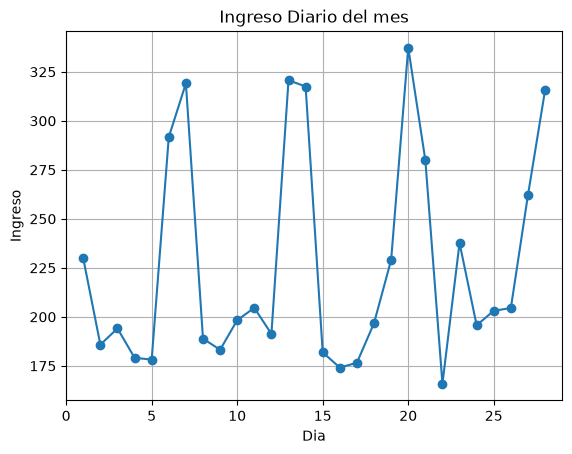

In [65]:
fig,ax =plt.subplots()
x=range(1,29)

ax.plot(x,ingreso_diario.ravel(),marker="o")
ax.set_title("Ingreso Diario del mes")
ax.set_xlabel("Dia")
ax.set_ylabel("Ingreso")
ax.grid(True,alpha=1)
ax.set_xlim(0,29)
plt.show()

#### **Ejercicio 16.** Quiero comparar cuánto dinero generó cada producto en el mes.

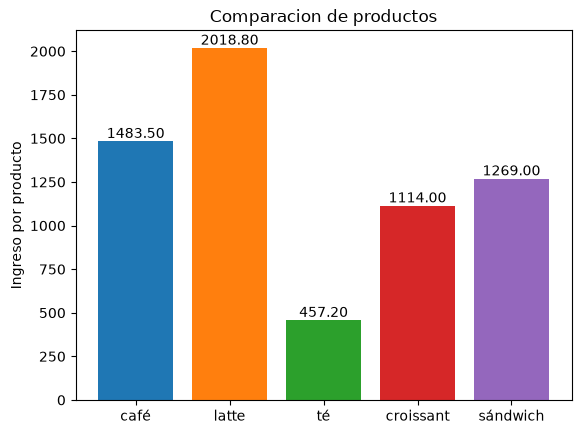

In [66]:
fig,ax = plt.subplots()

prod=ax.bar(productos,ingresoP, color=["C0","C1","C2","C3","C4"])
ax.bar_label(prod,fmt="%.2f")
ax.set_ylabel("Ingreso por producto")
ax.set_title("Comparacion de productos")
plt.show()

#### **Ejercicio 17.** Quiero ver en un mismo gráfico las unidades vendidas cada día de los 5 productos, una línea por producto.

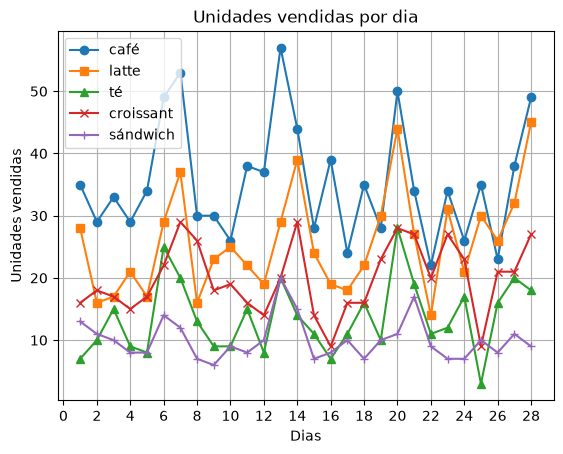

In [129]:
fig,ax = plt.subplots()
lines=["-","--",":","-.","--"]
markers=["o","s","^","x","+"]
for i in range(len(productos)):
    ax.plot(x,ventas[:,i],
            marker=f"{markers[i]}",
            markersize=6,
            linewidth=1.5,
            label=f"{productos[i]}")
ax.legend()
ax.grid(True,alpha=1)
ax.set_ylabel("Unidades vendidas")
ax.set_xlabel("Dias")
ax.set_title("Unidades vendidas por dia")
ax.set_xticks(range(0,29,2))
plt.show()

#### **Ejercicio 18.** Quiero ver la matriz de ventas (días × productos) como un mapa de calor.

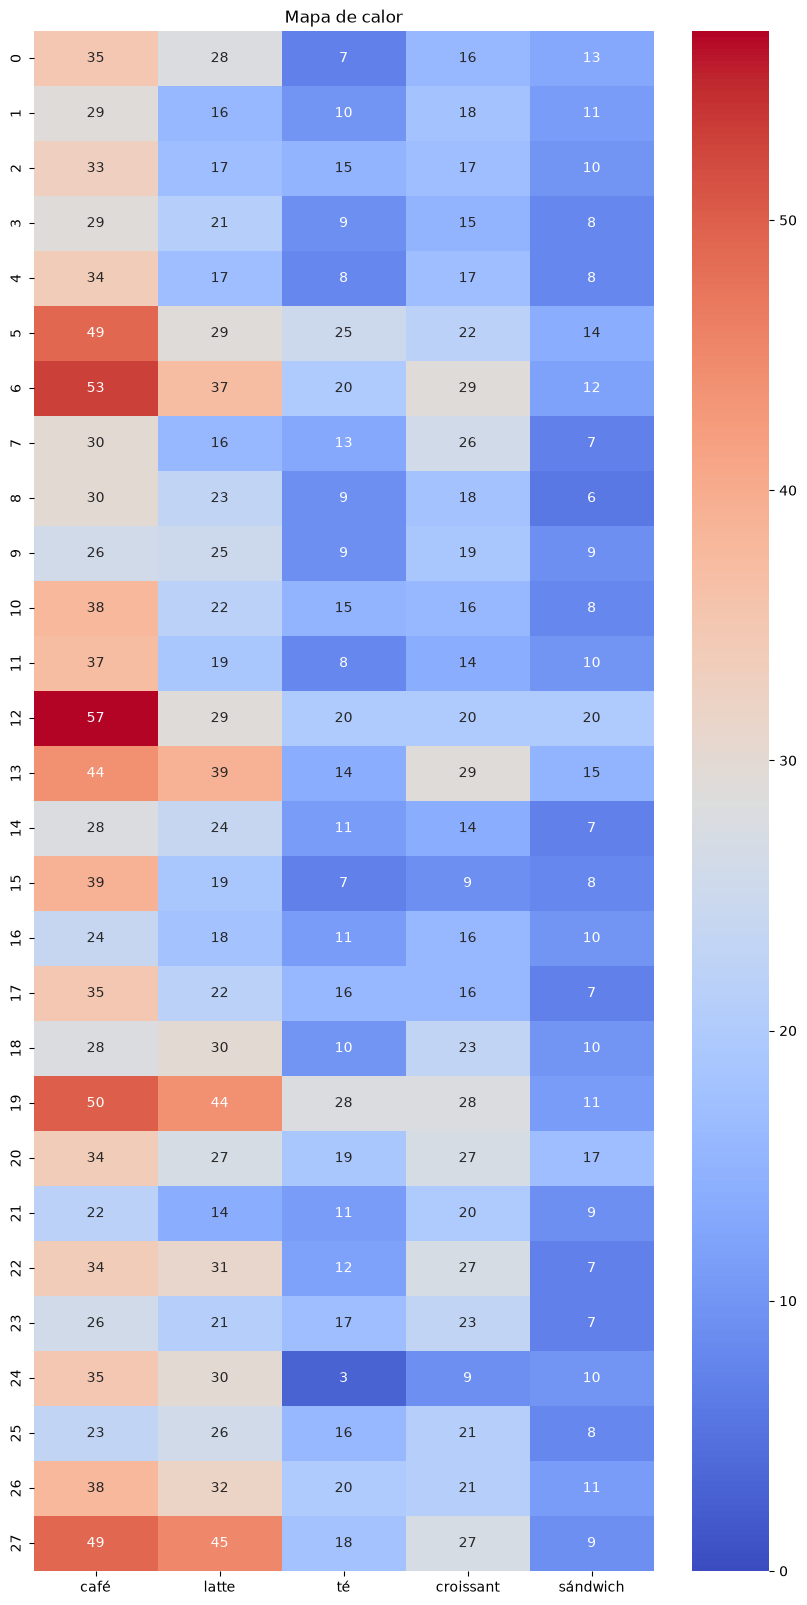

In [148]:
ventasdata= pd.DataFrame(ventas,columns=productos)

fig,ax = plt.subplots(figsize=(10,20))
sns.heatmap(ventasdata,
            annot=True,
            cmap="coolwarm",
            vmin=0,
            vmax=ventas.max(),
            ax=ax)
ax.set_title("Mapa de calor")
plt.show()

### Con los datos de las propinas 💵

Usa el DataFrame `propinas` tal como quedó al final de la Parte 2.

#### **Ejercicio 19.** Quiero ver el histograma del importe de la cuenta.

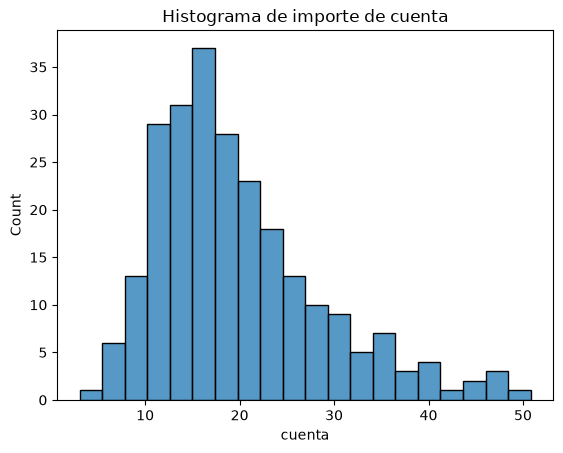

In [162]:
fig,ax = plt.subplots()
sns.histplot(data=propinas,x="cuenta",bins=20,ax=ax)
ax.set_title("Histograma de importe de cuenta")
plt.show()

#### **Ejercicio 20.** Quiero visualizar la relación entre la cuenta y la propina.

/tmp/ipykernel_4370/3999070940.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(bbox_to_anchor=(1.02,1),loc="upper left")


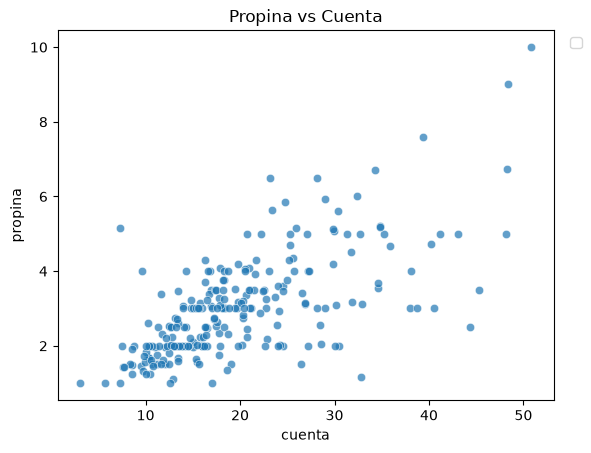

In [173]:
fig,ax = plt.subplots()
sns.scatterplot(data=propinas,x="cuenta",y="propina",alpha=0.7,ax=ax)
ax.set_title("Propina vs Cuenta")
ax.legend(bbox_to_anchor=(1.02,1),loc="upper left")
plt.show()

####  **Ejercicio 21.** Quiero ver esa misma relación, pero distinguiendo las comidas de las cenas.

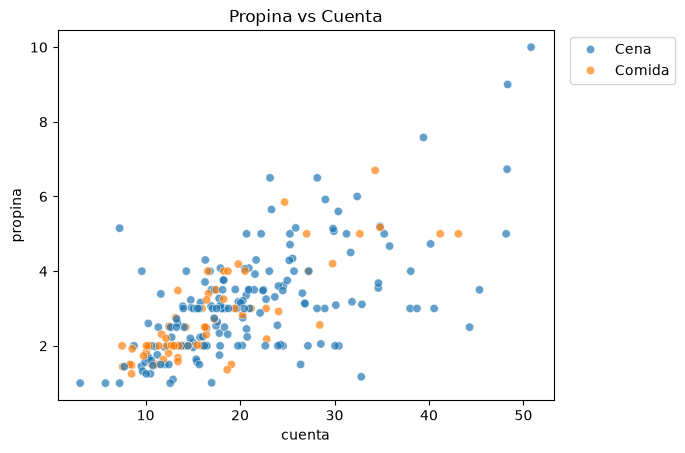

In [172]:
fig,ax = plt.subplots()
sns.scatterplot(data=propinas,x="cuenta",y="propina",hue="momento",alpha=0.7,ax=ax)
ax.set_title("Propina vs Cuenta")
ax.legend(bbox_to_anchor=(1.02,1),loc="upper left")
plt.show()

#### **Ejercicio 22.** Quiero ver si hay valores atípicos en el porcentaje de propina de cada día de la semana.

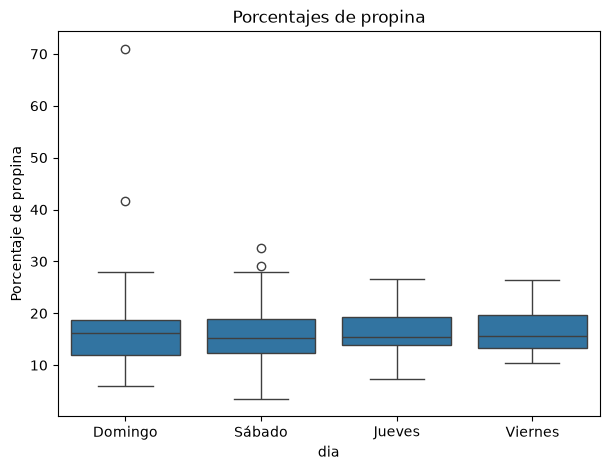

In [203]:
fig,ax=plt.subplots(figsize=(7,5))
sns.boxplot(data=propinas,x="dia",y="pct_propina",ax=ax)
ax.set_title("Porcentajes de propina")
ax.set_ylabel("Porcentaje de propina")
plt.show()

#### **Ejercicio 23.** Quiero ver cuántas mesas se atendieron cada día.

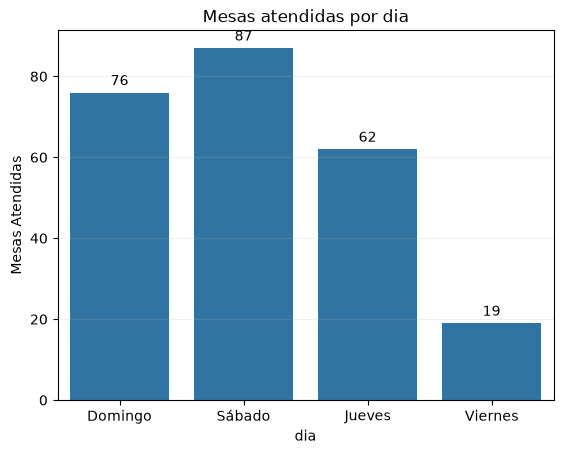

In [202]:
fig,ax = plt.subplots()
grafico=sns.countplot(data=propinas,x="dia",ax=ax)
ax.set_title("Mesas atendidas por dia")
ax.bar_label(grafico.containers[0],padding=3)
ax.set_ylabel("Mesas Atendidas")
ax.grid(True,axis="y",alpha=0.2)
plt.show()

#### **Ejercicio 24.** Quiero comparar la propina media según el número de personas en la mesa, separando mesas de fumadores y de no fumadores.

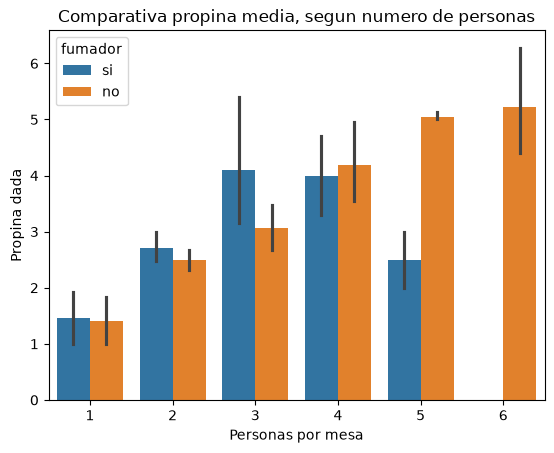

In [205]:
fig,ax = plt.subplots()
sns.barplot(data=propinas,x="personas",y="propina",hue="fumador",ax=ax)
ax.set_title("Comparativa propina media, segun numero de personas")
ax.set_ylabel("Propina dada")
ax.set_xlabel("Personas por mesa")
plt.show()

### Con un dataset nuevo: los pingüinos 🐧

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies de la Antártida:

| Columna | Significado |
|---|---|
| `species` | especie: `Adelie`, `Chinstrap`, `Gentoo` |
| `island` | isla donde se registró |
| `bill_length_mm` | longitud del pico (mm) |
| `bill_depth_mm` | profundidad (altura) del pico (mm) |
| `flipper_length_mm` | longitud de la aleta (mm) |
| `body_mass_g` | peso (g) |
| `sex` | `Male` / `Female` |

**Ejercicio 25.** Carga los datos en un DataFrame llamado `pinguinos`. Quiero ver el histograma del peso de los pingüinos.

In [199]:
pinguinos=pd.read_csv(DATA_DIR/"penguins.csv")
pinguinos.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


#### **Ejercicio 26.** Quiero ver si la distribución del peso cambia según la especie.

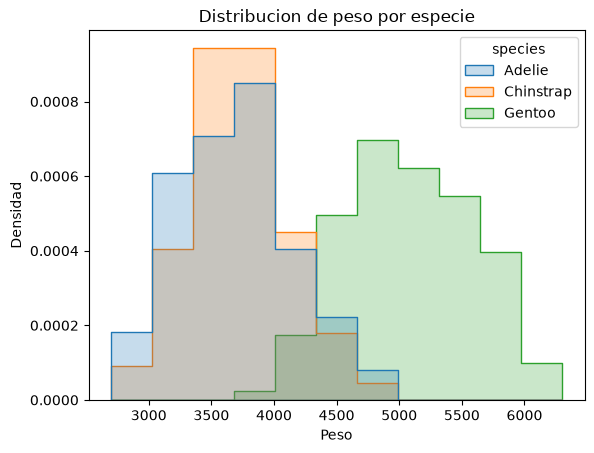

In [206]:
fig,ax = plt.subplots()
sns.histplot(data=pinguinos,
             x="body_mass_g",
             hue="species",
             stat="density",
             common_norm=False,
             element="step",
             ax=ax)
ax.set_title("Distribucion de peso por especie")
ax.set_xlabel("Peso")
ax.set_ylabel("Densidad")
plt.show()

#### **Ejercicio 27.** Quiero ver si hay valores atípicos en la longitud de la aleta de cada especie.

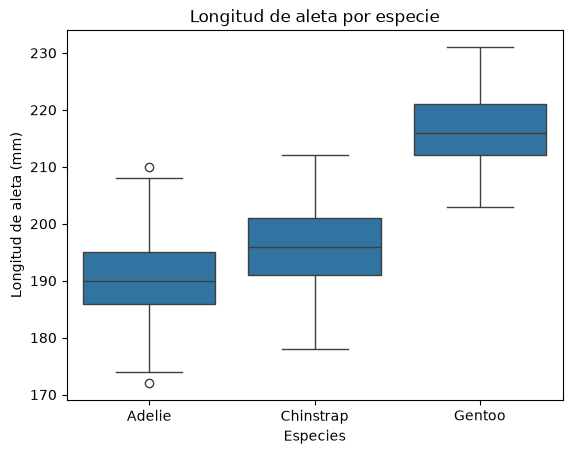

In [209]:
fig,ax = plt.subplots()
sns.boxplot(data=pinguinos,x="species",y="flipper_length_mm",ax=ax)
ax.set_title("Longitud de aleta por especie")
ax.set_xlabel("Especies")
ax.set_ylabel("Longitud de aleta (mm)")
plt.show()

#### **Ejercicio 28.** Quiero visualizar la relación entre la longitud y la profundidad del pico, distinguiendo las especies.

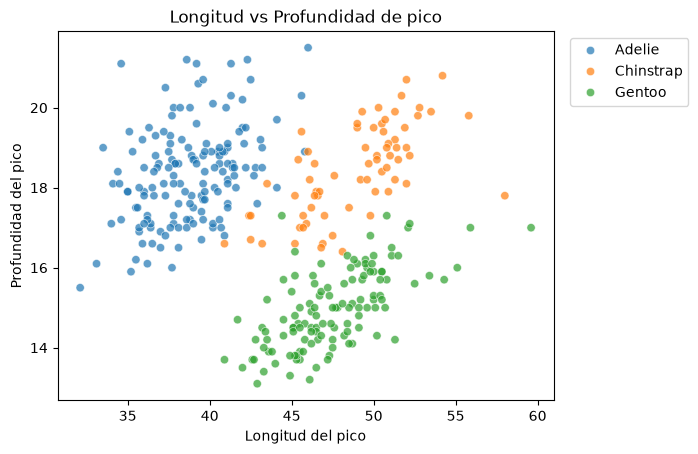

In [213]:
fig,ax=plt.subplots()
sns.scatterplot(data=pinguinos,
               x="bill_length_mm",
               y="bill_depth_mm",
               hue="species",
               alpha=0.7,
               ax=ax)
ax.legend(bbox_to_anchor=(1.02,1),loc="upper left")
ax.set_title("Longitud vs Profundidad de pico")
ax.set_ylabel("Profundidad del pico")
ax.set_xlabel("Longitud del pico")
plt.show()

#### **Ejercicio 29.** Quiero ver en una sola figura el histograma de las cuatro medidas numéricas, cada una en su propio gráfico.

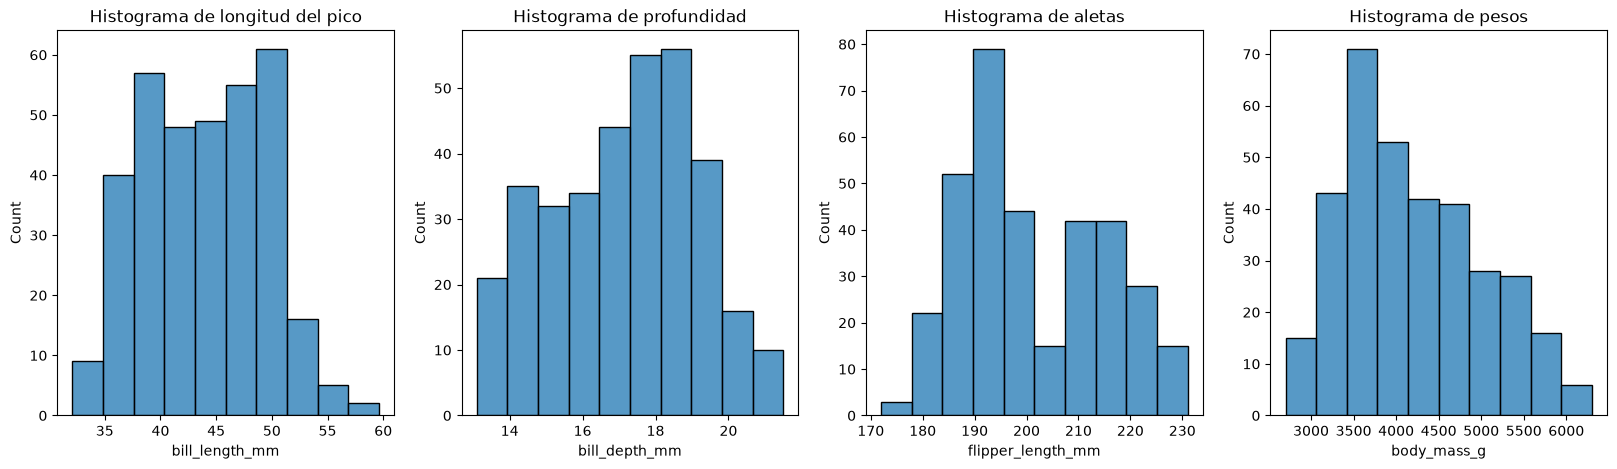

In [222]:
fig,axes = plt.subplots(1,4,figsize=(20,5))
sns.histplot(data=pinguinos,x="bill_length_mm",bins=10,ax=axes[0])
axes[0].set_title("Histograma de longitud del pico")

sns.histplot(data=pinguinos,x="bill_depth_mm",bins=10,ax=axes[1])
axes[1].set_title("Histograma de profundidad")

sns.histplot(data=pinguinos,x="flipper_length_mm",bins=10,ax=axes[2])
axes[2].set_title("Histograma de aletas")

sns.histplot(data=pinguinos,x="body_mass_g",bins=10,ax=axes[3])
axes[3].set_title("Histograma de pesos")

plt.show()

#### **Ejercicio 30.** Quiero ver qué medidas numéricas están más relacionadas entre sí.

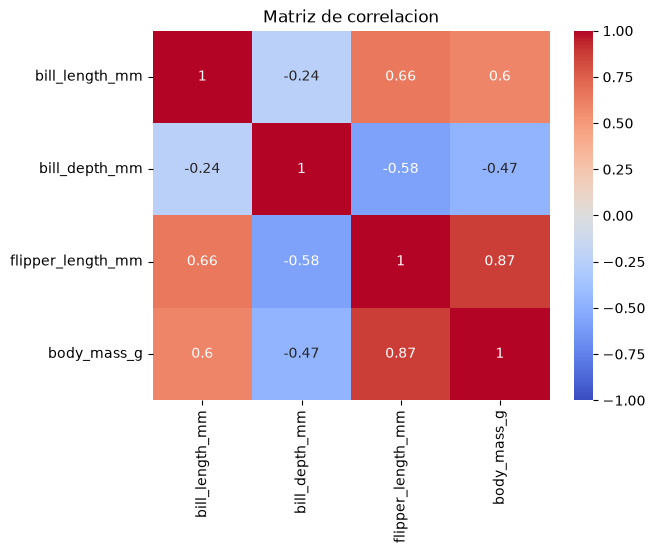

In [226]:
corr=pinguinos[["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]].corr()
fig,ax=plt.subplots()
sns.heatmap(corr,annot=True,cmap="coolwarm",vmin=-1,vmax=1,ax=ax)
ax.set_title("Matriz de correlacion")
plt.show()

**Ejercicio 31.** Quiero comparar el peso medio de cada especie, separando machos y hembras.

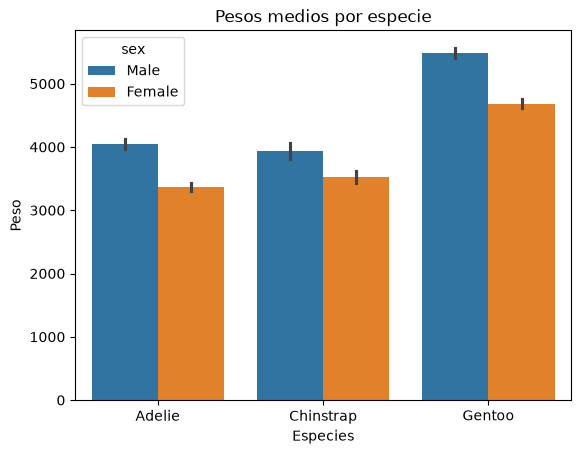

In [228]:
fig,ax=plt.subplots()
sns.barplot(data=pinguinos,x="species",y="body_mass_g",hue="sex",ax=ax)
ax.set_title("Pesos medios por especie")
ax.set_ylabel("Peso")
ax.set_xlabel("Especies")
plt.show()

---
## Reto opcional · El Titanic 🚢

En 1912 el Titanic se hundió en su viaje inaugural. El archivo `data/titanic.csv` tiene información de 891 pasajeros. Las columnas que necesitas:

| Columna | Significado |
|---|---|
| `survived` | 1 si sobrevivió, 0 si no |
| `sex` | `male` / `female` |
| `age` | edad (¡algunas faltan!) |
| `fare` | precio del billete |
| `class` | clase del billete: `First`, `Second`, `Third` |

**Pregunta:** ¿se cumplió el famoso *"las mujeres y los niños primero"*? ¿Importaba la clase del billete?

a) Carga los datos y usa `info()` para ver qué columnas tienen valores faltantes.

b) ¿Qué proporción de pasajeros sobrevivió?

c) Calcula la tasa de supervivencia por **sexo**, por **clase** y en una tabla dinámica **sexo × clase**.

d) Agrupa las edades en `"niño"` (0–12), `"adolescente"` (13–18), `"adulto"` (19–60) y `"mayor"` (más de 60), y calcula la tasa de supervivencia y el número de pasajeros de cada grupo.

e) ¿Cuánto costaba de media el billete en cada clase?

> 💡 **Pistas:**
> - La **media** de una columna de 0 y 1 es la **proporción** de unos: `titanic["survived"].mean()` es la tasa de supervivencia.
> - Para d), `pd.cut` con `bins=[0, 12, 18, 60, 100]`. Los pasajeros sin edad (`NaN`) quedan fuera de los grupos automáticamente.

In [61]:
# Tu código aquí

In [62]:
# Tu código aquí

In [63]:
# Tu código aquí

✍️ **Pregunta:** ¿se cumplió *"las mujeres y los niños primero"*? ¿Y la clase, importaba? Responde con números.

✍️ **Tu respuesta:** 